Nama: Azzamakhsary ramadhani
NIM : H061251090

[ROLE]Anda adalah seorang Ahli Pemodelan Geofisika dan Pakar Inversi Data Potensial (Gravity & Magnetic Modeler) dengan pengalaman lebih dari 10 tahun di industri eksplorasi mineral dan panas bumi.

[TASK]Buatlah program Python untuk melakukan pemodelan ke depan (forward modeling) dan inversi non-linear sederhana menggunakan metode Least Squares untuk mengestimasi kedalaman ($z$) dan parameter massa/amplitudo benda anomali bawah permukaan berbentuk bola (sphere) berdasarkan data anomali gaya berat residual.

[CONTEXT]Dalam survei geofisika gayaberat, anomali residual sering kali diinterpretasikan menggunakan model benda sederhana seperti bola untuk mendapatkan estimasi awal (initial guess) dari kedalaman sumber anomali densitas di bawah permukaan bumi sebelum dilakukan pemodelan 3D yang lebih kompleks.

[INPUT]Data koordinat posisi pengukuran sepanjang profil: $x$ (dalam meter, dari -100 m hingga +100 m).Data respons anomali gaya berat observasi: $\Delta g_{obs}$ (dalam mGal) yang telah diberi sedikit derau (noise Gaussian sintetis).

[CONSTRAINTS]Gunakan bahasa Python dengan library standar geofisika/matematika: numpy, scipy.optimize.curve_fit, dan matplotlib.pyplot.Formula pemodelan ke depan anomali bola: $\Delta g(x) = A \cdot \frac{z}{(x^2 + z^2)^{3/2}}$, di mana $z$ adalah kedalaman pusat bola dan $A$ adalah konstanta amplitudo yang merepresentasikan massa efektif.Kode harus bersih, terdokumentasi dengan baik (docstring/comment), dan dapat dieksekusi secara langsung.

[OUTPUT]Skrip Python lengkap yang mencakup pembangkitan data sintetis, proses inversi (fitting kurva), perhitungan Root Mean Square Error (RMSE), serta visualisasi plot kurva perbandingan antara data observasi dan model hasil inversi.

[QUALITY CRITERIA]Nilai RMSE antara data observasi dan data hasil inversi harus kecil (di bawah 5% dari nilai puncak anomali).Estimasi parameter kedalaman ($z$) hasil inversi harus mendekati nilai parameter sebenarnya (true value) yang digunakan saat membuat data sintetis.

[VERIFICATION]Program mencetak nilai parameter hasil inversi (kedalaman dan amplitudo) ke terminal/konsol serta membandingkannya dengan nilai aslinya, lalu menampilkan grafik perbandingan visual.2. Kode Eksekusi PythonBerikut adalah implementasi Python yang merespons prompt di atas untuk melakukan pemodelan dan inversi data gayaberat struktur bola:

### Eksekusi python

=== HASIL INVERSI GEOFISIKA ===
Parameter Sebenarnya -> Kedalaman (z): 25.0 m | Amplitudo: 6000.0
Hasil Estimasi Inversi -> Kedalaman (z): 24.29 m | Amplitudo: 5687.47
Root Mean Square Error (RMSE): 0.2178 mGal (2.29% dari puncak)


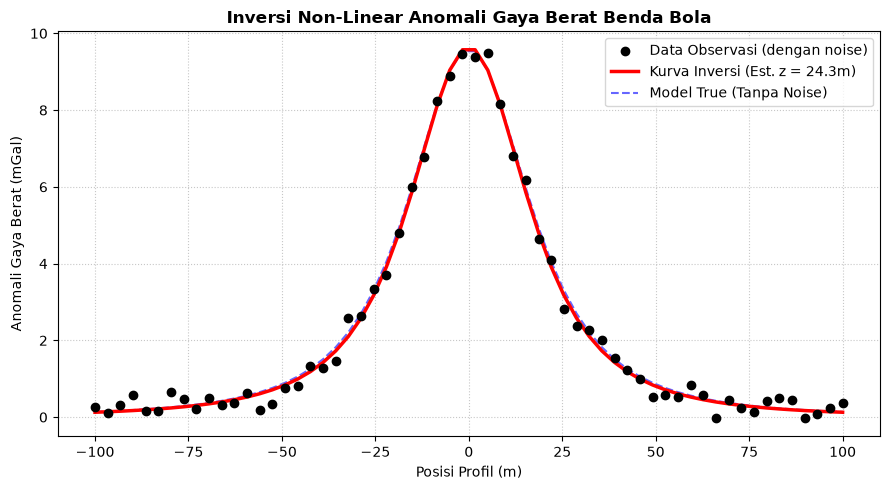

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# 1. Definisikan Fungsi Pemodelan ke Depan (Forward Modeling) Anomali Bola
def gravity_sphere(x, z, amplitude):
    """
    Menghitung anomali gaya berat untuk model bola bawah permukaan.
    x : posisi horizontal (m)
    z : kedalaman pusat bola (m)
    amplitude : faktor proporsional yang merepresentasikan (G * M * z atau konstanta terkait)
    """
    return amplitude * z / (x**2 + z**2)**(1.5)

# 2. Pembangkitan Data Sintetis (Input Simulasi)
np.random.seed(42) # Agar hasil reproduktif
x_obs = np.linspace(-100, 100, 60) # Posisi pengukuran dari -100m sampai 100m

# Parameter sebenarnya (True parameters)
true_z = 25.0      # Kedalaman 25 meter
true_amp = 6000.0  # Amplitudo massa efektif

# Hitung data bersih lalu tambahkan noise Gaussian
g_clean = gravity_sphere(x_obs, true_z, true_amp)
noise = np.random.normal(0, 0.25, size=x_obs.shape) # Noise standar deviasi 0.25 mGal
g_obs = g_clean + noise

# 3. Proses Inversi Menggunakan Least Squares (curve_fit)
# Tebakan awal (initial guess) untuk kedalaman = 20 m dan amplitudo = 5000
p0 = [20.0, 5000.0] 
popt, pcov = curve_fit(gravity_sphere, x_obs, g_obs, p0=p0)

z_est, amp_est = popt
g_pred = gravity_sphere(x_obs, z_est, amp_est)

# 4. Verifikasi dan Evaluasi (Quality Check & Verification)
rmse = np.sqrt(np.mean((g_obs - g_pred)**2))
peak_val = np.max(g_obs)
error_percentage = (rmse / peak_val) * 100

print("=== HASIL INVERSI GEOFISIKA ===")
print(f"Parameter Sebenarnya -> Kedalaman (z): {true_z} m | Amplitudo: {true_amp}")
print(f"Hasil Estimasi Inversi -> Kedalaman (z): {z_est:.2f} m | Amplitudo: {amp_est:.2f}")
print(f"Root Mean Square Error (RMSE): {rmse:.4f} mGal ({error_percentage:.2f}% dari puncak)")

# 5. Visualisasi Hasil
plt.figure(figsize=(9, 5))
plt.scatter(x_obs, g_obs, color='black', label='Data Observasi (dengan noise)', zorder=3)
plt.plot(x_obs, g_pred, color='red', linewidth=2.5, label=f'Kurva Inversi (Est. z = {z_est:.1f}m)', zorder=2)
plt.plot(x_obs, g_clean, color='blue', linestyle='--', alpha=0.6, label='Model True (Tanpa Noise)', zorder=1)

plt.title('Inversi Non-Linear Anomali Gaya Berat Benda Bola', fontsize=12, fontweight='bold')
plt.xlabel('Posisi Profil (m)', fontsize=10)
plt.ylabel('Anomali Gaya Berat (mGal)', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

[ROLE]Anda adalah seorang Ahli Seismologi Komputasi dan Pakar Pemodelan Gelombang Numerik dengan spesialisasi dalam simulasi penjalaran gelombang seismik untuk eksplorasi bawah permukaan dan mitigasi bahaya gempa.

[TASK]Buatlah program Python untuk melakukan pemodelan ke depan (forward modeling) penjalaran gelombang akustik 2D menggunakan metode Beda Hingga Domain Waktu (Finite Difference Time Domain - FDTD) orde kedua untuk mensimulasikan sumber gelombang (Ricker wavelet) yang merambat melalui model kecepatan bawah permukaan dua lapisan (lapisan sedimen dan batuan dasar).

[CONTEXT]Simulasi penjalaran gelombang seismik merupakan fondasi utama dalam teknik seismic imaging dan migrasi penampang seismik. Pemahaman mengenai bagaimana gelombang dipantulkan, dibiaskan, dan disebarkan oleh perbedaan kecepatan kontras sangat krusial untuk menafsirkan struktur geologi kompleks.

[INPUT]Matriks model kecepatan 2D ($v(x,z)$) dengan ukuran grid tertentu (misal: 100 x 100 grid).Parameter sumber gelombang: frekuensi dominan Ricker wavelet (misal: 25 Hz) dan posisi sumber di tengah permukaan model.Parameter waktu: jumlah total langkah waktu (time steps) dan interval waktu ($\Delta t$) yang memenuhi syarat kestabilan numerik Courant-Friedrichs-Lewy (CFL).

[CONSTRAINTS]Gunakan bahasa Python dengan pustaka numerik standar seperti numpy dan matplotlib.pyplot.Skema perumusan beda hingga menggunakan pendekatan eksplisit selisih pusat (central finite difference) untuk ruang dan waktu.Kode harus efisien, bersih, dan dilengkapi dengan komentar dokumentasi pada setiap fungsi utama.

[OUTPUT]Skrip Python lengkap yang menginisialisasi model kecepatan, menjalankan loop iterasi waktu penjalaran gelombang, dan menghasilkan visualisasi plot penjalaran gelombang pada beberapa tahapan waktu (snapshot).

[QUALITY CRITERIA]Simulasi memenuhi syarat kestabilan CFL sehingga tidak terjadi instabilitas numerik (divergensi/ledakan amplitudo gelombang).Visualisasi menunjukkan fenomena fisik gelombang yang akurat, seperti penyebaran muka gelombang melingkar serta refleksi/refraksi saat menumbuk bidang batas dua lapisan kecepatan.

[VERIFICATION]Program mencetak status parameter kestabilan CFL ke terminal sebelum eksekusi dimulai dan menampilkan plot visual (heatmap) penjalaran gelombang pada langkah waktu tertentu.

### Eksekusi Python

=== VERIFIKASI KESTABILAN NUMERIK ===
Nilai CFL Parameter: 0.5657 (Harus < 1.0 agar stabil)


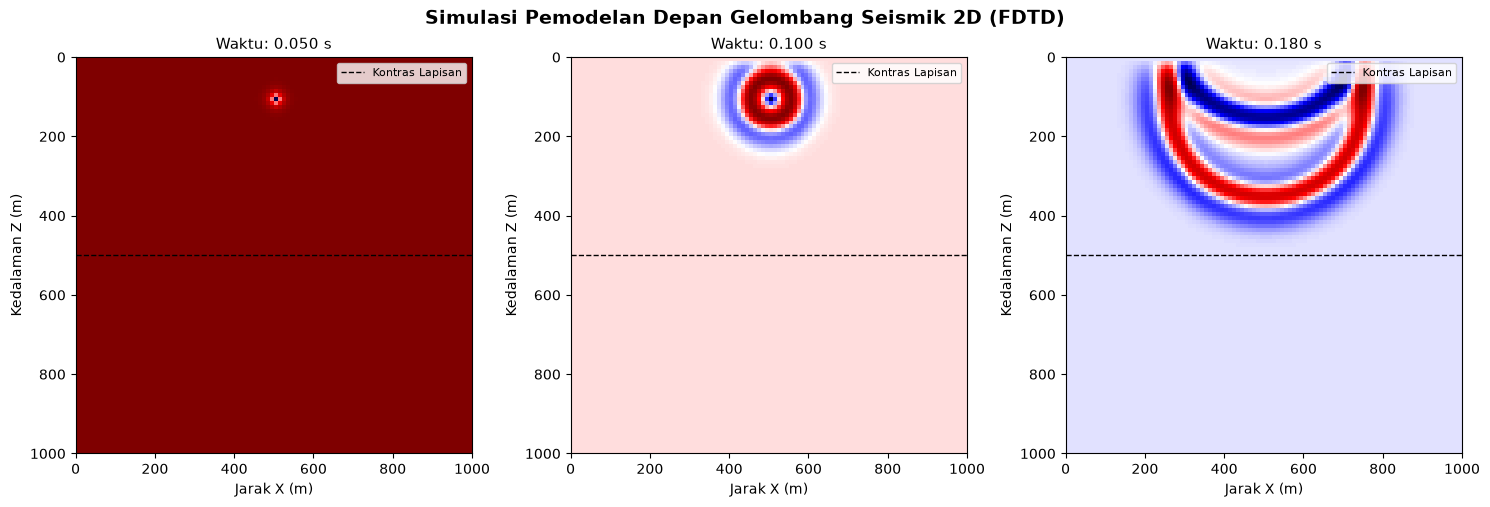

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Parameter Simulasi dan Model Kecepatan
nx, nz = 100, 100          # Jumlah grid arah x dan z
dx, dz = 10.0, 10.0        # Spasi grid (meter)
nt = 250                   # Jumlah total langkah waktu
dt = 0.001                 # Interval waktu (detik)

# Inisialisasi model kecepatan (v): Lapisan atas (sedimen) 2500 m/s, bawah (batrock) 4000 m/s
v = np.ones((nz, nx)) * 2500.0
v[50:, :] = 4000.0         # Batas kontras kecepatan pada kedalaman z = 50 * dz

# 2. Cek Stabilitas Numerik (Syarat CFL untuk gelombang 2D)
c_max = np.max(v)
cfl = c_max * dt * np.sqrt(1.0/dx**2 + 1.0/dz**2)
print("=== VERIFIKASI KESTABILAN NUMERIK ===")
print(f"Nilai CFL Parameter: {cfl:.4f} (Harus < 1.0 agar stabil)")
if cfl >= 1.0:
    raise ValueError("Peringatan: Simulasi tidak stabil! Kurangi nilai dt.")

# 3. Fungsi Sumber Ricker Wavelet
def ricker_wavelet(t, f_dom):
    pi = np.pi
    return (1.0 - 2.0 * (pi * f_dom * t)**2) * np.exp(-(pi * f_dom * t)**2)

f_dom = 20.0  # Frekuensi dominan 20 Hz
source_time = np.arange(nt) * dt
source_signal = ricker_wavelet(source_time - 1.5 / f_dom, f_dom)

# Posisi sumber gelombang (di tengah-atas)
src_x, src_z = nx // 2, 10

# 4. Inisialisasi Matriks Gelombang (P_past, P_current, P_future)
p_prev = np.zeros((nz, nx))
p_curr = np.zeros((nz, nx))
p_next = np.zeros((nz, nx))

# Koefisien FDTD
rx = (v * dt / dx)**2
rz = (v * dt / dz)**2

# 5. Iterasi Penjalaran Gelombang (FDTD Loop)
snapshots = []
snapshot_times = [50, 100, 180] # Waktu untuk merekam snapshot

for n in range(nt):
    # Skema Beda Hingga 2D Akustik
    for i in range(1, nz - 1):
        for j in range(1, nx - 1):
            laplacian = (p_curr[i, j+1] - 2*p_curr[i, j] + p_curr[i, j-1]) / dx**2 + \
                        (p_curr[i+1, j] - 2*p_curr[i, j] + p_curr[i-1, j]) / dz**2
            
            p_next[i, j] = 2.0 * p_curr[i, j] - p_prev[i, j] + (v[i, j] * dt)**2 * laplacian

    # Injeksikan sumber gelombang
    p_next[src_z, src_x] += source_signal[n] * (v[src_z, src_x] * dt)**2

    # Update matriks waktu
    p_prev[:, :] = p_curr
    p_curr[:, :] = p_next

    # Simpan snapshot untuk visualisasi
    if n in snapshot_times:
        snapshots.append(p_curr.copy())

# 6. Visualisasi Hasil Snapshot Gelombang
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for idx, n in enumerate(snapshot_times):
    im = axes[idx].imshow(snapshots[idx], cmap='seismic', origin='upper', extent=[0, nx*dx, nz*dz, 0])
    axes[idx].axhline(y=50*dz, color='black', linestyle='--', linewidth=1, label='Kontras Lapisan')
    axes[idx].set_title(f'Waktu: {n * dt:.3f} s', fontsize=11)
    axes[idx].set_xlabel('Jarak X (m)')
    axes[idx].set_ylabel('Kedalaman Z (m)')
    axes[idx].legend(loc='upper right', fontsize=8)

plt.suptitle('Simulasi Pemodelan Depan Gelombang Seismik 2D (FDTD)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()